# 6주차 결과 시각화

위험관리를 적용하기 전(base)과 후(all)를 같은 기간, 같은 비용으로 비교했다. 결과 이미지는 `results/plots/`에 저장했다.

In [1]:
import os, sys, json, re
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if Path.cwd().name == "week06":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from core.config import load_json
from week06.backtest import load_leg, past_volatility, run_backtest, trading_days

plt.rcParams["font.family"] = "Apple SD Gothic Neo"
plt.rcParams["axes.unicode_minus"] = False

config = load_json("week06/config.json")
settings = config["backtest"]
legs = [load_leg(leg["symbol"], settings) for leg in config["legs"]]
days, _ = trading_days(legs, config["session"])
volatility = past_volatility(legs, days, config)

results = {}
for version in ["base", "all"]:
    rules = {**config["rules"], **config["versions"][version]}
    results[version] = run_backtest(legs, days, volatility, rules, config, settings["slippage_ticks"])

out = Path("week06/results/plots")
out.mkdir(parents=True, exist_ok=True)

## 1. 위험관리 적용 전후 누적 손익

점선은 비교 구간 경계다(독립 확인 9/14 ~ 9/29, 4주차 기간 9/30 ~ 11/9, 금 하락 11/10 ~ 11/20).

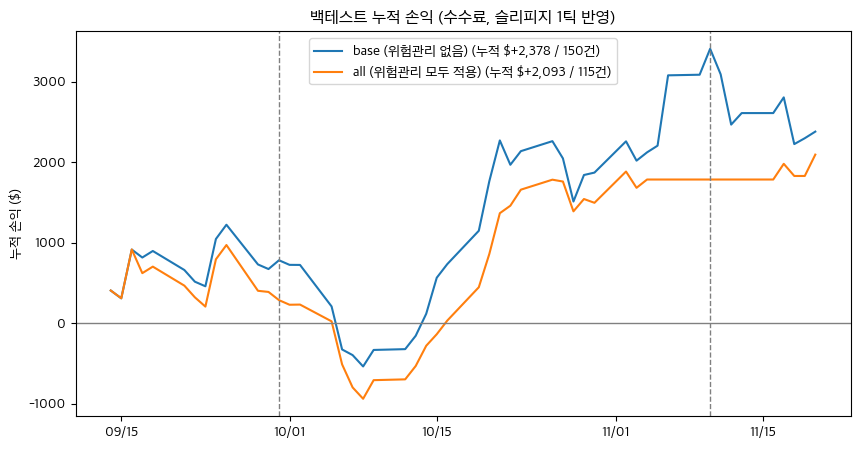

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))

xs = [datetime.strptime(day, "%Y%m%d") for day in days]
for version, label in [("base", "base (위험관리 없음)"), ("all", "all (위험관리 모두 적용)")]:
    total, ys = 0, []
    for day in days:
        total += results[version]["daily"][day]
        ys.append(total)
    ax.plot(xs, ys, label=f"{label} (누적 ${total:+,.0f} / {len(results[version]['trades'])}건)")

for start, _ in list(settings["periods"].values())[1:]:
    ax.axvline(datetime.strptime(start, "%Y%m%d"), color="gray", linestyle="--", linewidth=1)
ax.axhline(0, color="gray", linewidth=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
ax.set_title("백테스트 누적 손익 (수수료, 슬리피지 1틱 반영)")
ax.set_ylabel("누적 손익 ($)")
ax.legend()
fig.savefig(out / "1_base_vs_all_equity.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. 거래별 손익 분포

4주차는 1분 종가로 금액 손절을 판단해 −$300보다 크게 잃은 거래가 있었다. 실시간 손절을 넣은 뒤 이 거래가 남는지 확인했다.

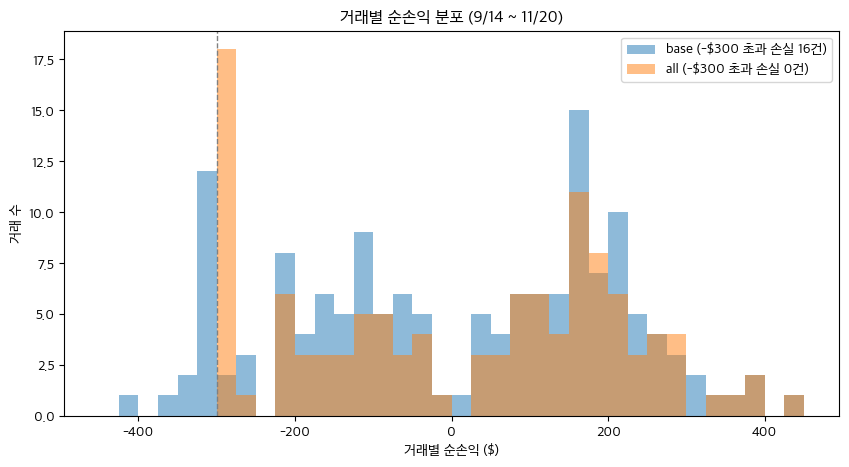

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

bins = range(-450, 451, 25)
for version, label in [("base", "base"), ("all", "all")]:
    nets = [t.net for t in results[version]["trades"]]
    over = sum(net < -config["strategy"]["max_loss"] for net in nets)
    ax.hist(nets, bins=bins, alpha=0.5, label=f"{label} (-$300 초과 손실 {over}건)")

ax.axvline(-config["strategy"]["max_loss"], color="gray", linestyle="--", linewidth=1)
ax.set_title("거래별 순손익 분포 (9/14 ~ 11/20)")
ax.set_xlabel("거래별 순손익 ($)")
ax.set_ylabel("거래 수")
ax.legend()
fig.savefig(out / "2_trade_pnl_hist.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. 모의투자 신호와 진입을 막은 사유

`events_*.jsonl`에서 신호 기록만 추렸다. 손절 작동 테스트(`stop_test_*` 폴더)는 제외했다.

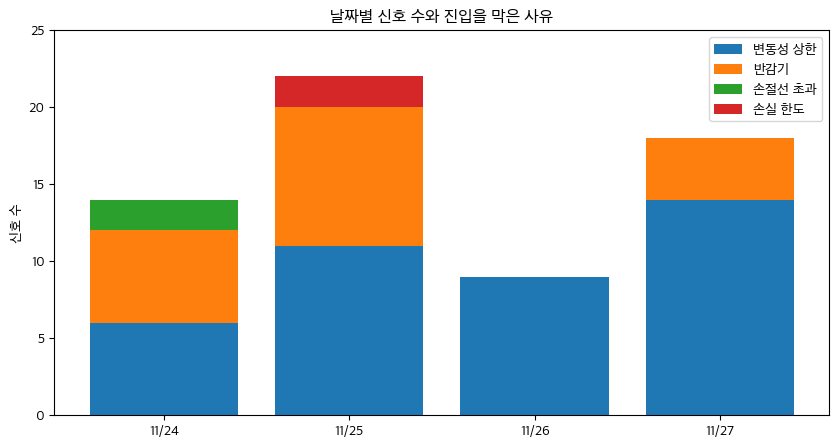

In [4]:
blocked = {}
for path in sorted(Path("week06/results").glob("events_*.jsonl")):
    day = path.stem.split("_")[1]
    counts = blocked.setdefault(day, Counter())
    for line in path.read_text().splitlines():
        event = json.loads(line)
        if event["event"] == "신호":
            match = re.search(r"\((.+)\)", event["data"]["진입"])
            counts[match.group(1) if match else "진입"] += 1

reasons = sorted({r for counts in blocked.values() for r in counts}, key=lambda r: -sum(c[r] for c in blocked.values()))
labels = [f"{day[4:6]}/{day[6:]}" for day in blocked]

fig, ax = plt.subplots(figsize=(10, 5))
bottom = [0] * len(blocked)
for reason in reasons:
    values = [counts[reason] for counts in blocked.values()]
    ax.bar(labels, values, bottom=bottom, label=reason)
    bottom = [b + v for b, v in zip(bottom, values)]

ax.set_title("날짜별 신호 수와 진입을 막은 사유")
ax.set_ylabel("신호 수")
ax.set_ylim(0, max(bottom) + 3)
ax.legend()
fig.savefig(out / "3_live_signals.png", dpi=150, bbox_inches="tight")
plt.show()